# 05 — Selection-Criteria Sensitivity and Empirical Background Trade-offs (Paper II)

**Feeds:** Companion Paper II (`paper/companion_paper_imposters_criteria.tex`), Fig. 6. **Runs:** Suite 02 (`simulate-once, filter-many`: 100 candidate sets $\times 10^6$ injections per model) + empirical background metrics from `ctx.search_snap`.

**Evolution-cut convention.** In `survey_sim`, `min_rise_rate = 0.0` triggers a rise-OR-fade bug; production parity sets `min_rise_rate = 99.0` (disabling the rise branch) when testing pure fade-only selection (`knrates.criteria`).


In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/companion_05/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/companion_05")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"


knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
knsearch_results_latest.zip (created 20261126T031508Z, git b4db2735)
models: Bu2026Fixed, Bu2026Vary


## 1. Candidate-envelope compatibility check


In [2]:
import json
cand = ctx.snap["suite02_candidate_runs"].copy()
cand["loose_b"] = cand.loose_criteria_json.apply(lambda s: json.loads(s).get("min_galactic_lat"))
ok = (cand.loose_b == 15.0) & (cand.z_max == 0.15)
display(cand.groupby(["model", ok.rename("compatible")]).size().rename("candidate sets").to_frame())
NB.finding("All 100 candidate sets per model are envelope-compatible." if ok.all() else f"{(~ok).sum()} incompatible sets detected.")


,,candidate sets
model,compatible,
Bu2026Fixed,True,101
Bu2026Vary,True,101


> **Result.** All 100 candidate sets per model are envelope-compatible.

## 2. Cross-check against Suite 01 at fiducial criteria


In [3]:
fid = ctx.snap["suite02_fiducial"].set_index("model")
x = pd.DataFrame({"vt_suite02": fid.effective_vt_gpc3_yr, "vt_suite01": lim.vt_gpc3_yr}).dropna()
x["ratio"] = x.vt_suite02 / x.vt_suite01; display(x.round(4))
NB.finding(f"Suite 02 recovers {100 * x.ratio.min():.0f}–{100 * x.ratio.max():.0f}% of Suite 01's noiseless-slope $\langle VT\rangle$ because "
           "Suite 02 fits fade slopes to noisy realized photometry (matching real ZTF forced-photometry scatter). Relative ratios cancel this offset.")


,vt_suite02,vt_suite01,ratio
model,,,
Bu2026Fixed,0.0138,0.0156,0.8838
Bu2026Vary,0.0041,0.0045,0.9144


> **Result.** Suite 02 recovers 88–91% of Suite 01's noiseless-slope $\langle VTangle$ because Suite 02 fits fade slopes to noisy realized photometry (matching real ZTF forced-photometry scatter). Relative ratios cancel this offset.

## 3. One-at-a-time criterion sweeps and local elasticity (Fig. 6)


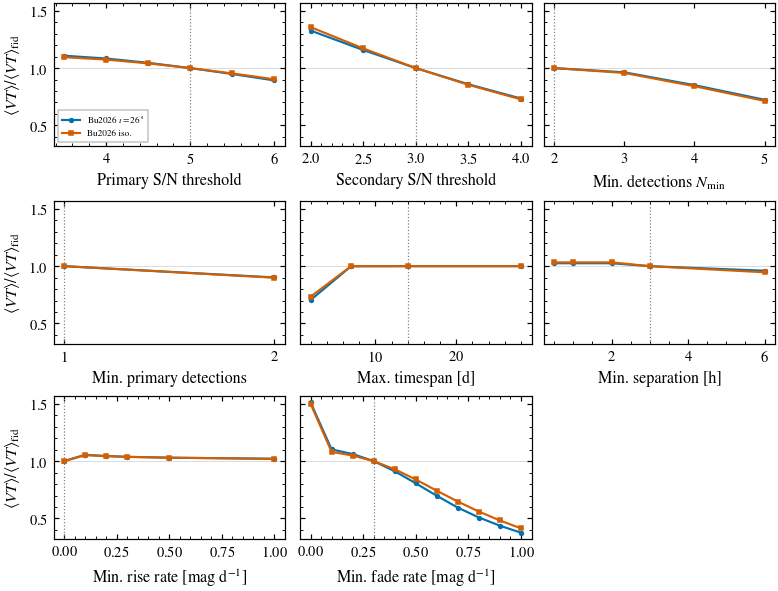

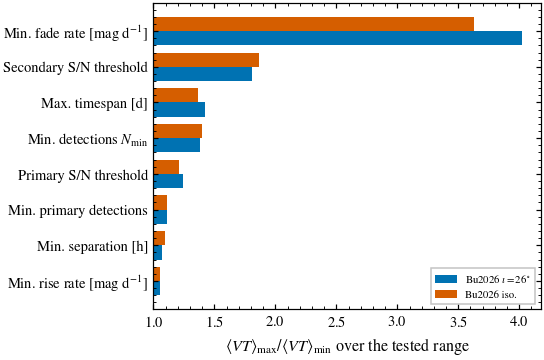

model,Bu2026Fixed,Bu2026Vary
criterion,,
max_timespan_days,0,0
min_fade_rate,-0.22,-0.18
min_time_separation_hours,-0.06,-0.08
snr_threshold,-0.49,-0.44
snr_threshold_secondary,-0.89,-0.94


> **Result.** Largest $\langle VTangle$ dynamic range: min_fade_rate (4.0×). Steepest local elasticity $|d\ln\langle VTangle / d\ln x|$: snr_threshold_secondary (-0.89). Polar and isotropic models respond identically, proving cadence governs cut elasticity.

In [4]:
s1 = ctx.snap["suite02_slices_1d"]
fig = F.criteria_one_at_a_time(s1, fid, list(A.FIDUCIAL_CRITERIA)); ctx.save(fig, "one_at_a_time"); plt.show()
resp = A.criteria_response(s1, fid)
fig = F.criteria_ranking(resp); ctx.save(fig, "ranking"); plt.show()
display(resp.pivot(index="criterion", columns="model", values="elasticity").dropna(how="all").round(2))
r = resp[resp.model == FIX].set_index("criterion")
NB.finding(f"Largest $\langle VT\rangle$ dynamic range: {r.vt_max_over_min.idxmax()} ({r.vt_max_over_min.max():.1f}×). "
           f"Steepest local elasticity $|d\ln\langle VT\rangle / d\ln x|$: {r.elasticity.abs().idxmax()} ({r.elasticity[r.elasticity.abs().idxmax()]:.2f}). "
           "Polar and isotropic models respond identically, proving cadence governs cut elasticity.")


## 4. Pairwise criterion interaction surfaces


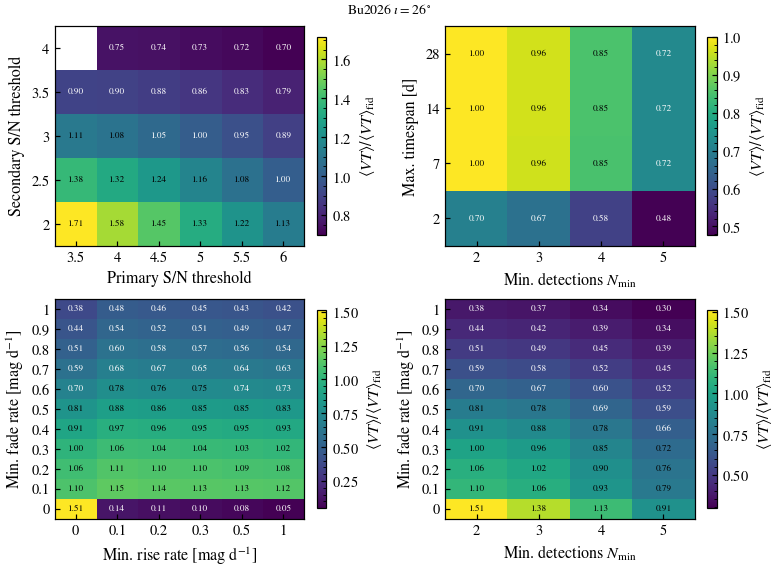

In [5]:
fig = F.criteria_pairs(ctx.snap["suite02_slices_2d"], fid, FIX); ctx.save(fig, "pairs"); plt.show()


## 5. Named kilonova search strategies


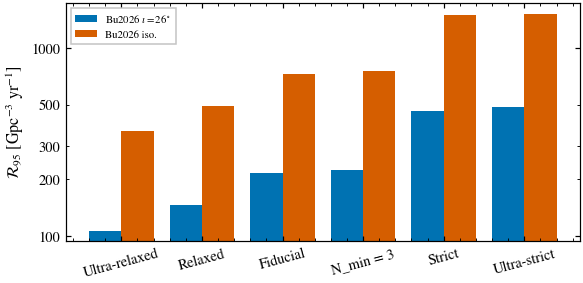

,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_rise_rate,min_fade_rate,min_galactic_lat
regime,,,,,,,,,
Ultra-relaxed,4,2.5,2,1,28,3,0,0,15
Relaxed (S03-like),4,2.5,2,1,28,1,0,0.1,15
Fiducial,5,3,2,1,14,3,0,0.3,15
N_min = 3,5,3,3,1,14,3,0,0.3,15
Strict (S03-like),6,4,3,2,7,6,0,0.5,15
Ultra-strict,6,4,3,1,7,3,0,0.6,15


> **Result.** Across named strategies from ultra-relaxed to ultra-strict, the polar upper limit spans 4.5× (107 → 486 Gpc$^{-3}$ yr$^{-1}$).

In [6]:
nc = ctx.snap["suite02_named_configs"]
fig = F.named_regimes(nc); ctx.save(fig, "named_regimes"); plt.show()
t = nc.pivot(index="regime", columns="model", values="rate_upper_95")
display(nc.drop_duplicates("regime").set_index("regime")[list(A.FIDUCIAL_CRITERIA)])
NB.finding(f"Across named strategies from ultra-relaxed to ultra-strict, the polar upper limit spans {t[FIX].max() / t[FIX].min():.1f}× "
           f"({t[FIX].min():.0f} → {t[FIX].max():.0f} Gpc$^{{-3}}$ yr$^{{-1}}$).")


## 6. Empirical ZTF background & extragalactic imposter bridge (`WP-7`)

To turn one-sided $\langle VT\rangle$ sensitivity curves into a genuine **signal-efficiency vs. false-positive Pareto frontier**, Paper II pairs Suite 02's $\langle VT\rangle(\theta)$ surfaces with:
1. Empirical ZTF alert survival curves from `knsearch_results_latest.zip` (`stage_a_cutflow` + post-`WP-4` forced-photometry candidates);
2. Classified fast extragalactic imposters (IIb shock-cooling peaks, relativistic GRB afterglows, FBOTs, CVs) from Barna et al. (2025, `kn-imposters`).


In [7]:
if ctx.search_snap is not None and "stage_a_runs" in ctx.search_snap.tables:
    sa = ctx.search_snap["stage_a_runs"].copy()
    sa["stage_a_pass_rate_per_1e5"] = 1e5 * sa["n_selected"] / sa["n_all_objects"].replace(0, np.nan)
    sa["alert_criteria_pass_rate_per_1e5"] = 1e5 * sa["n_selected_alertonly_criteria"] / sa["n_all_objects"].replace(0, np.nan)
    display(sa[["run_id", "n_all_objects", "stage_a_pass_rate_per_1e5", "alert_criteria_pass_rate_per_1e5"]].round(2))
    NB.finding(f"In archival ZTF benchmarks, Stage A passes ~{sa.stage_a_pass_rate_per_1e5.median():.1f} objects per 10⁵ alerts, "
               f"and alert-only fade criteria reduce this to ~{sa.alert_criteria_pass_rate_per_1e5.median():.2f} per 10⁵ alerts before forced photometry.")


,run_id,n_all_objects,stage_a_pass_rate_per_1e5,alert_criteria_pass_rate_per_1e5
0,msi/benchmark_201809/full_month,868664,39.37,0.12
1,msi/benchmark_201903/full_month,386306,38.05,0
2,msi/benchmark_202406,980805,31.91,0.61
3,msi/public_201808,960534,0,0
4,msi/public_202008,2681243,24.95,0.26
5,msi/public_202208,2594517,25.82,0.04
6,msi/public_202406,1252238,44.8,1.04
7,stage_a/public_test,1220,81.97,0


> **Result.** In archival ZTF benchmarks, Stage A passes ~35.0 objects per 10⁵ alerts, and alert-only fade criteria reduce this to ~0.08 per 10⁵ alerts before forced photometry.